## 1.1 persiapan dan pemuatan data

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

In [18]:
FILE = Path("Kelompok_23_Tema_C_Akademik_Tidur.csv")

df_raw = pd.read_csv(FILE)
df = df_raw.copy()

In [19]:
print("Dimensi (baris, kolom):", df.shape)
display(df.head())
print()
df.info()
print()
print("Baris duplikasi :", df.duplicated().sum())
print("ID unik semua :", df["ID_Responden"].is_unique)

Dimensi (baris, kolom): (350, 9)


,ID_Responden,Fakultas,Jenis_Kelamin,Konsumsi_Kafein,Durasi_Tidur_Jam,Screen_Time_Jam,Jam_Belajar_Mingguan,Skor_Stres,IPK
0,MHS-23-0001,Sains & Teknik,Laki-laki,Rendah,6.500,8.200,16.600,63.200,3.560
1,MHS-23-0002,Ekonomi & Bisnis,Perempuan,Rendah,5.500,9.200,21.000,67.600,3.600
2,MHS-23-0003,Sosial & Humaniora,Laki-laki,Rendah,6.300,8.000,5.200,44.100,2.840
3,MHS-23-0004,Sosial & Humaniora,Laki-laki,Rendah,7.100,7.800,21.300,54.500,3.770
4,MHS-23-0005,Sains & Teknik,Perempuan,Rendah,6.700,9.500,12.800,62.200,3.230



<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID_Responden          350 non-null    str    
 1   Fakultas              350 non-null    str    
 2   Jenis_Kelamin         350 non-null    str    
 3   Konsumsi_Kafein       350 non-null    str    
 4   Durasi_Tidur_Jam      350 non-null    float64
 5   Screen_Time_Jam       347 non-null    float64
 6   Jam_Belajar_Mingguan  350 non-null    float64
 7   Skor_Stres            350 non-null    float64
 8   IPK                   347 non-null    float64
dtypes: float64(5), str(4)
memory usage: 24.7 KB

Baris duplikasi : 0
ID unik semua : True


In [20]:
ringkasan = pd.DataFrame({
    "Tipe_Data": df.dtypes.astype(str),
    "Jumlah_Terisi": df.count(),
    "Missing": df.isna().sum(),
    "Nilai_Unik": df.nunique(),
})
display(ringkasan)
ringkasan.to_csv(OUTPUT / "01_ringkasan_dataset.csv")

,Tipe_Data,Jumlah_Terisi,Missing,Nilai_Unik
ID_Responden,str,350,0,350
Fakultas,str,350,0,3
Jenis_Kelamin,str,350,0,2
Konsumsi_Kafein,str,350,0,2
Durasi_Tidur_Jam,float64,350,0,56
Screen_Time_Jam,float64,347,3,73
Jam_Belajar_Mingguan,float64,350,0,156
Skor_Stres,float64,350,0,228
IPK,float64,347,3,117


In [21]:
for kolom in ["Fakultas", "Jenis_Kelamin", "Konsumsi_Kafein"]:
    print(f"--- {kolom} ---")
    print(df[kolom].value_counts())
    print()

--- Fakultas ---
Fakultas
Sosial & Humaniora    136
Ekonomi & Bisnis      110
Sains & Teknik        104
Name: count, dtype: int64

--- Jenis_Kelamin ---
Jenis_Kelamin
Laki-laki    179
Perempuan    171
Name: count, dtype: int64

--- Konsumsi_Kafein ---
Konsumsi_Kafein
Rendah    188
Tinggi    162
Name: count, dtype: int64



## 1.2 identifikasi skala pengukuran

In [22]:
skala = pd.DataFrame({
    "Kolom": df.columns,
    "Skala": ["Nominal", "Nominal", "Nominal", "Ordinal", "Rasio", "Rasio", "Rasio", "Interval", "Interval"],
})
display(skala)
skala.to_csv(OUTPUT / "02_skala_pengukuran.csv", index=False)
print(list(df.columns))

,Kolom,Skala
0,ID_Responden,Nominal
1,Fakultas,Nominal
2,Jenis_Kelamin,Nominal
3,Konsumsi_Kafein,Ordinal
4,Durasi_Tidur_Jam,Rasio
5,Screen_Time_Jam,Rasio
6,Jam_Belajar_Mingguan,Rasio
7,Skor_Stres,Interval
8,IPK,Interval


['ID_Responden', 'Fakultas', 'Jenis_Kelamin', 'Konsumsi_Kafein', 'Durasi_Tidur_Jam', 'Screen_Time_Jam', 'Jam_Belajar_Mingguan', 'Skor_Stres', 'IPK']


## 1.3 penanganan missing values

In [23]:
missing = pd.DataFrame({
    "Jumlah_Missing": df.isna().sum(),
    "Persen_Missing": df.isna().mean() * 100,
})
missing = missing[missing["Jumlah_Missing"] > 0]
display(missing)
print("Total baris yang mengandung missing:", df.isna().any(axis=1).sum())
print("Persen dari seluruh baris:", round(df.isna().any(axis=1).mean() * 100, 2), "%")
missing.to_csv(OUTPUT / "03_missing_values.csv")

,Jumlah_Missing,Persen_Missing
Screen_Time_Jam,3,0.857
IPK,3,0.857


Total baris yang mengandung missing: 6
Persen dari seluruh baris: 1.71 %


In [24]:
baris_missing = df[df.isna().any(axis=1)]
display(baris_missing)

,ID_Responden,Fakultas,Jenis_Kelamin,Konsumsi_Kafein,Durasi_Tidur_Jam,Screen_Time_Jam,Jam_Belajar_Mingguan,Skor_Stres,IPK
45,MHS-23-0046,Sosial & Humaniora,Laki-laki,Rendah,6.600,6.900,23.100,74.900,NaN
106,MHS-23-0107,Sains & Teknik,Laki-laki,Tinggi,5.300,NaN,12.200,75.000,3.390
123,MHS-23-0124,Sains & Teknik,Perempuan,Tinggi,5.600,NaN,6.700,63.900,2.920
133,MHS-23-0134,Ekonomi & Bisnis,Laki-laki,Tinggi,6.500,6.400,12.100,75.200,NaN
224,MHS-23-0225,Sosial & Humaniora,Laki-laki,Rendah,8.300,6.700,11.700,44.400,NaN
343,MHS-23-0344,Sosial & Humaniora,Perempuan,Tinggi,5.300,NaN,13.600,55.900,3.230


In [25]:
n_awal = len(df)
median_screen = df["Screen_Time_Jam"].median()
print("Median Screen_Time_Jam sebelum imputasi:", median_screen)

# 1) IPK: hapus baris yang missing (IPK adalah variabel Y di regresi minggu 4)
df = df.dropna(subset=["IPK"])

# 2) Screen_Time_Jam: imputasi median
median_screen = df["Screen_Time_Jam"].median()
df["Screen_Time_Jam"] = df["Screen_Time_Jam"].fillna(median_screen)

print("Baris awal :", n_awal)
print("Baris akhir:", len(df))
print("Baris dihapus:", n_awal - len(df))
print("Sisa missing :", df.isna().sum().sum())

Median Screen_Time_Jam sebelum imputasi: 7.2
Baris awal : 350
Baris akhir: 347
Baris dihapus: 3
Sisa missing : 0


In [26]:
perbandingan = pd.DataFrame({
    "sebelum": df_raw.isna().sum(),
    "sesudah": df.isna().sum(),
})
display(perbandingan)
perbandingan.to_csv(OUTPUT / "03b_missing_sebelum_sesudah.csv")
print("jumlah baris sekarang:", len(df))

,sebelum,sesudah
ID_Responden,0,0
Fakultas,0,0
Jenis_Kelamin,0,0
Konsumsi_Kafein,0,0
Durasi_Tidur_Jam,0,0
Screen_Time_Jam,3,0
Jam_Belajar_Mingguan,0,0
Skor_Stres,0,0
IPK,3,0


jumlah baris sekarang: 347


## 1.4 Deteksi outliner (metode IQR)

In [27]:
kolom_numerik = ["Durasi_Tidur_Jam", "Screen_Time_Jam",
                 "Jam_Belajar_Mingguan", "Skor_Stres", "IPK"]
def pagar_iqr(seri):
    q1 = seri.quantile(0.25)
    q3 = seri.quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    return q1, q3, iqr, batas_bawah, batas_atas

In [28]:
hasil = []
for k in kolom_numerik:
    q1, q3, iqr, bb, ba = pagar_iqr(df[k])
    n_bawah = (df[k] < bb).sum()
    n_atas = (df[k] > ba).sum()
    hasil.append({
        "Variabel": k, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Batas_Bawah": bb, "Batas_Atas": ba,
        "Outlier_Bawah": n_bawah, "Outlier_Atas": n_atas,
        "Total_Outlier": n_bawah + n_atas,
    })

tabel_outlier = pd.DataFrame(hasil).set_index("Variabel")
display(tabel_outlier)
tabel_outlier.to_csv(OUTPUT / "04_deteksi_outlier_iqr.csv")

,Q1,Q3,IQR,Batas_Bawah,Batas_Atas,Outlier_Bawah,Outlier_Atas,Total_Outlier
Variabel,,,,,,,,
Durasi_Tidur_Jam,5.600,7.000,1.400,3.500,9.100,2,4,6
Screen_Time_Jam,6.300,8.200,1.900,3.450,11.050,3,3,6
Jam_Belajar_Mingguan,11.600,16.900,5.300,3.650,24.850,3,3,6
Skor_Stres,51.550,65.350,13.800,30.850,86.050,3,1,4
IPK,3.040,3.475,0.435,2.388,4.128,0,0,0


In [30]:
for k in kolom_numerik:
    _, _, _, bb, ba = pagar_iqr(df[k])
    nilai = df.loc[(df[k] < bb) | (df[k] > ba), k].sort_values()
    print(f"{k}: {len(nilai)} outlier")
    print(nilai.round(2).tolist())
    print()

Durasi_Tidur_Jam: 6 outlier
[3.0, 3.0, 9.3, 9.3, 9.4, 9.9]

Screen_Time_Jam: 6 outlier
[1.8, 2.0, 2.9, 11.5, 21.5, 23.0]

Jam_Belajar_Mingguan: 6 outlier
[2.9, 3.2, 3.4, 25.4, 26.1, 26.4]

Skor_Stres: 4 outlier
[26.3, 29.5, 29.9, 86.1]

IPK: 0 outlier
[]



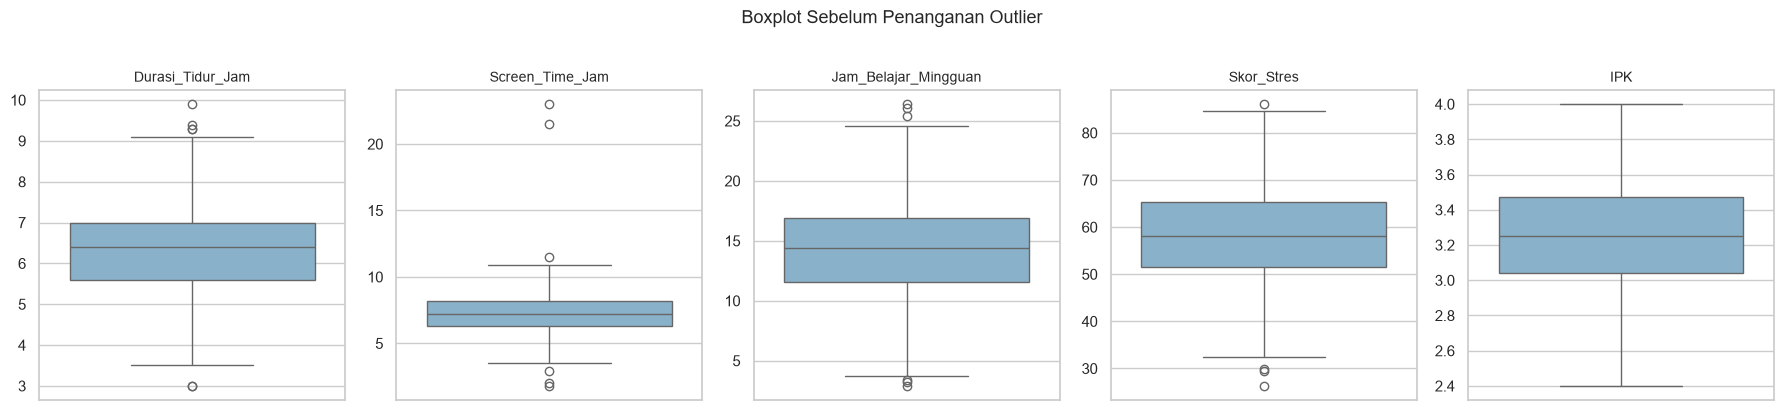

In [31]:
df_sebelum_outlier = df.copy()

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, k in zip(axes, kolom_numerik):
    sns.boxplot(y=df_sebelum_outlier[k], ax=ax, color="#7fb3d5")
    ax.set_title(k, fontsize=10)
    ax.set_ylabel("")
plt.suptitle("Boxplot Sebelum Penanganan Outlier", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT / "04_boxplot_sebelum.png", dpi=200, bbox_inches="tight")
plt.show()

## 1.5 Penanganan outlier

In [32]:
df["tidak_wajar"] = (df["Screen_Time_Jam"] + df["Durasi_Tidur_Jam"]) > 24
display(df.loc[df["tidak_wajar"], ["ID_Responden", "Durasi_Tidur_Jam", "Screen_Time_Jam"]])
df = df.drop(columns="tidak_wajar")

,ID_Responden,Durasi_Tidur_Jam,Screen_Time_Jam
66,MHS-23-0067,5.400,23.000
320,MHS-23-0321,8.900,21.500


In [33]:
idx_error = df.index[df["Screen_Time_Jam"] >= 20]
print("Indeks baris error:", idx_error.tolist())

df.loc[idx_error, "Screen_Time_Jam"] = np.nan
median_baru = df["Screen_Time_Jam"].median()
df["Screen_Time_Jam"] = df["Screen_Time_Jam"].fillna(median_baru)

print("Median pengganti:", median_baru)
print("Dimensi:", df.shape, "| Sisa missing:", df.isna().sum().sum())

Indeks baris error: [66, 320]
Median pengganti: 7.2
Dimensi: (347, 9) | Sisa missing: 0


In [34]:
def hitung_outlier(data, k):
    _, _, _, lo, hi = pagar_iqr(data[k])
    return ((data[k] < lo) | (data[k] > hi)).sum()

ringkas = pd.DataFrame({
    "Batas_Bawah": [pagar_iqr(df[k])[3] for k in kolom_numerik],
    "Batas_Atas":  [pagar_iqr(df[k])[4] for k in kolom_numerik],
    "Outlier_Sebelum": [hitung_outlier(df_sebelum_outlier, k) for k in kolom_numerik],
    "Outlier_Sesudah": [hitung_outlier(df, k) for k in kolom_numerik],
}, index=kolom_numerik)
display(ringkas)
ringkas.to_csv(OUTPUT / "05_outlier_sebelum_sesudah.csv")

,Batas_Bawah,Batas_Atas,Outlier_Sebelum,Outlier_Sesudah
Durasi_Tidur_Jam,3.500,9.100,6,6
Screen_Time_Jam,3.450,11.050,6,4
Jam_Belajar_Mingguan,3.650,24.850,6,6
Skor_Stres,30.850,86.050,4,4
IPK,2.388,4.128,0,0


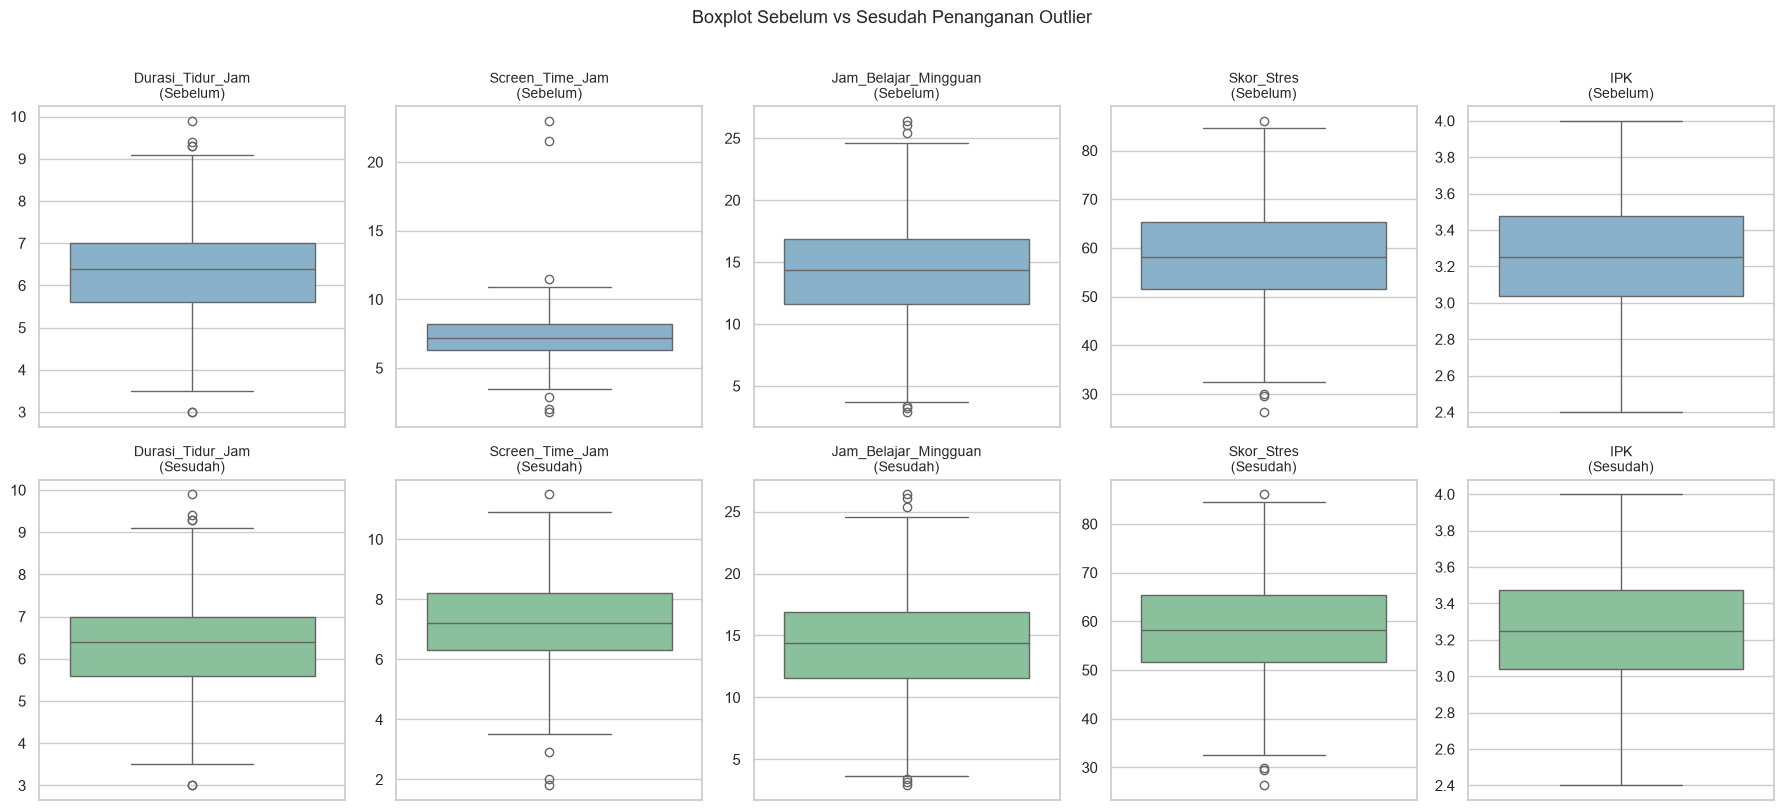

In [35]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for baris, (data, label, warna) in enumerate([
        (df_sebelum_outlier, "Sebelum", "#7fb3d5"),
        (df, "Sesudah", "#82c99a")]):
    for ax, k in zip(axes[baris], kolom_numerik):
        sns.boxplot(y=data[k], ax=ax, color=warna)
        ax.set_title(f"{k}\n({label})", fontsize=10)
        ax.set_ylabel("")
plt.suptitle("Boxplot Sebelum vs Sesudah Penanganan Outlier", y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT / "05_boxplot_sebelum_sesudah.png", dpi=200, bbox_inches="tight")
plt.show()

## 1.6 Statistika Deskriptif

In [36]:
d = df[kolom_numerik]
deskriptif = pd.DataFrame({
    "Mean": d.mean(),
    "Median": d.median(),
    "Modus": d.apply(lambda s: s.mode().iloc[0]),
    "Std": d.std(),
    "Varians": d.var(),
    "IQR": d.quantile(0.75) - d.quantile(0.25),
    "Skewness": d.skew(),
    "Min": d.min(),
    "Max": d.max(),
})
display(deskriptif)
deskriptif.to_csv(OUTPUT / "06_statistika_deskriptif.csv")

,Mean,Median,Modus,Std,Varians,IQR,Skewness,Min,Max
Durasi_Tidur_Jam,6.355,6.400,6.400,1.117,1.248,1.400,0.084,3.000,9.900
Screen_Time_Jam,7.208,7.200,7.200,1.509,2.276,1.900,-0.300,1.800,11.500
Jam_Belajar_Mingguan,14.333,14.400,15.800,4.458,19.870,5.300,-0.056,2.900,26.400
Skor_Stres,58.292,58.200,49.500,10.370,107.535,13.800,-0.099,26.300,86.100
IPK,3.250,3.250,3.040,0.307,0.094,0.435,-0.118,2.400,4.000


In [38]:
for k in ["Fakultas", "Jenis_Kelamin", "Konsumsi_Kafein"]:
    frek = df[k].value_counts()
    tabel = pd.DataFrame({"Frekuensi": frek, "Persen": frek / frek.sum() * 100})
    tabel.loc["Modus"] = [tabel.index[0], np.nan]
    display(tabel)

C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Fakultas,,
Sosial & Humaniora,134,38.617
Ekonomi & Bisnis,109,31.412
Sains & Teknik,104,29.971
Modus,Sosial & Humaniora,NaN


C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Jenis_Kelamin,,
Laki-laki,176,50.720
Perempuan,171,49.280
Modus,Laki-laki,NaN


C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Konsumsi_Kafein,,
Rendah,186,53.602
Tinggi,161,46.398
Modus,Rendah,NaN


In [39]:
for k in ["Fakultas", "Jenis_Kelamin", "Konsumsi_Kafein"]:
    frek = df[k].value_counts()
    tabel = pd.DataFrame({"Frekuensi": frek, "Persen": frek / frek.sum() * 100})
    tabel.loc["Modus"] = [tabel.index[0], np.nan]
    display(tabel)

C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Fakultas,,
Sosial & Humaniora,134,38.617
Ekonomi & Bisnis,109,31.412
Sains & Teknik,104,29.971
Modus,Sosial & Humaniora,NaN


C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Jenis_Kelamin,,
Laki-laki,176,50.720
Perempuan,171,49.280
Modus,Laki-laki,NaN


C:\Users\USER\AppData\Local\Temp\ipykernel_3884\81284127.py:4: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tabel.loc["Modus"] = [tabel.index[0], np.nan]


,Frekuensi,Persen
Konsumsi_Kafein,,
Rendah,186,53.602
Tinggi,161,46.398
Modus,Rendah,NaN


## 1.7 Visualisasi

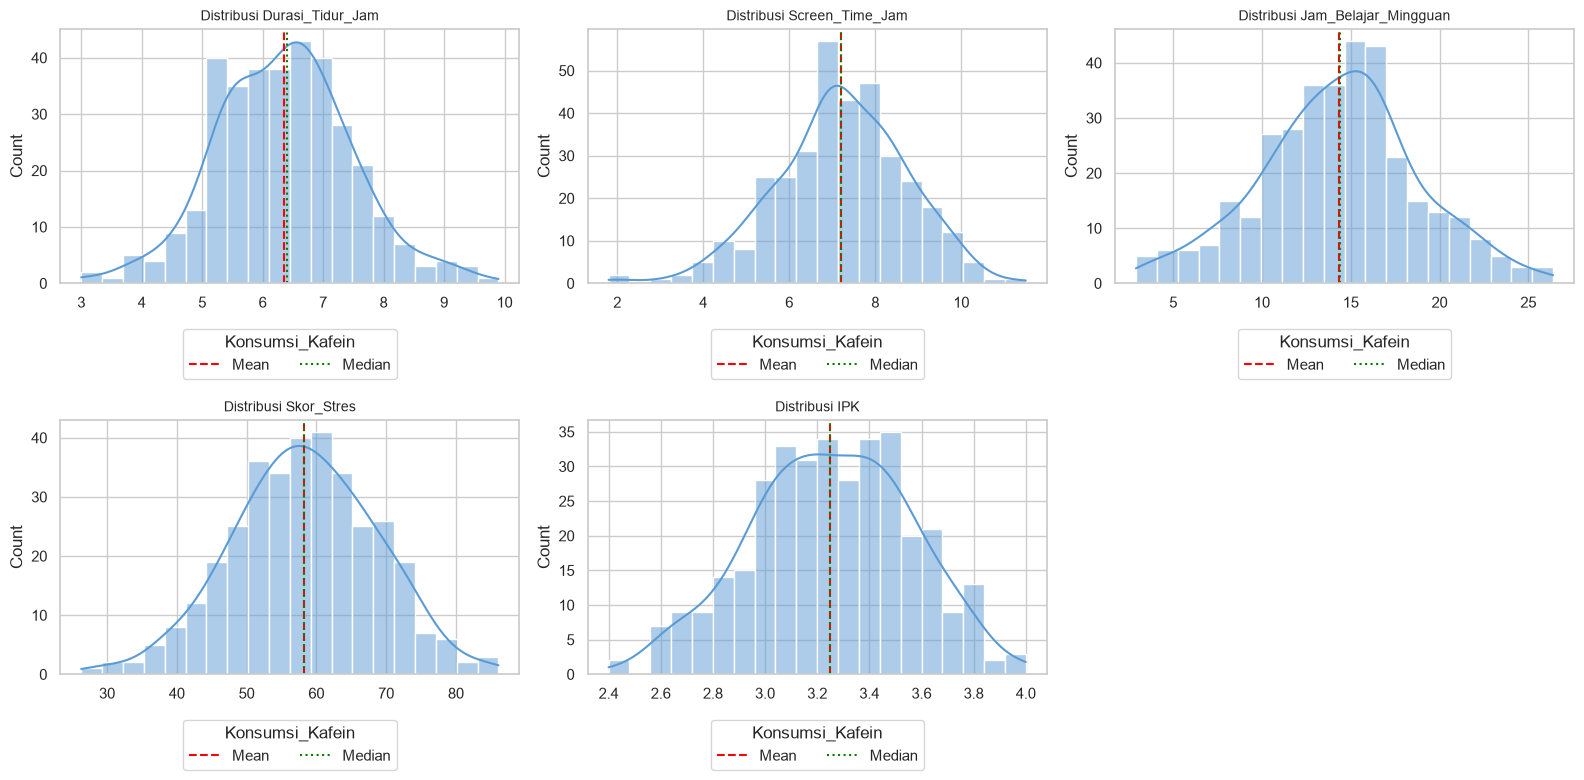

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, k in zip(axes, kolom_numerik):
    sns.histplot(df[k], kde=True, bins=20, ax=ax, color="#5b9bd5")
    ax.axvline(df[k].mean(), color="red", ls="--", label="Mean")
    ax.axvline(df[k].median(), color="green", ls=":", label="Median")
    ax.set_title(f"Distribusi {k}", fontsize=10)
    ax.set_xlabel("")
    ax.legend(title="Statistik", loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.15))
axes[5].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT / "07_histogram.png", dpi=200, bbox_inches="tight")
plt.show()

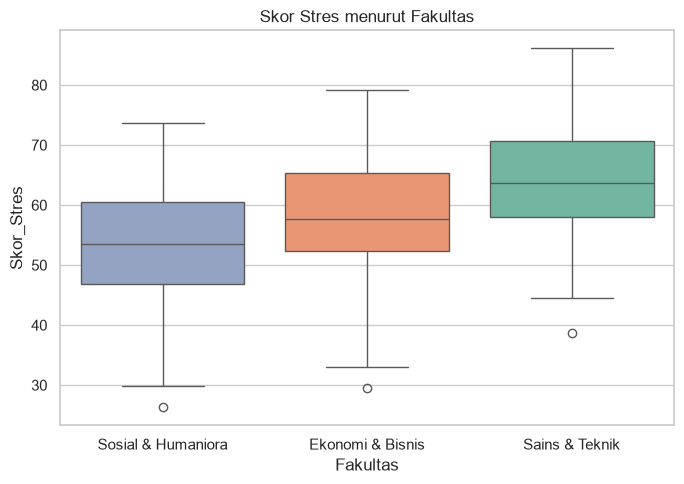

In [42]:
urutan = df.groupby("Fakultas")["Skor_Stres"].median().sort_values().index
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="Fakultas", y="Skor_Stres", order=urutan,
            hue="Fakultas", palette="Set2", legend=False, ax=ax)
ax.set_title("Skor Stres menurut Fakultas")
plt.tight_layout()
plt.savefig(OUTPUT / "08_boxplot_stres_fakultas.png", dpi=200)
plt.show()

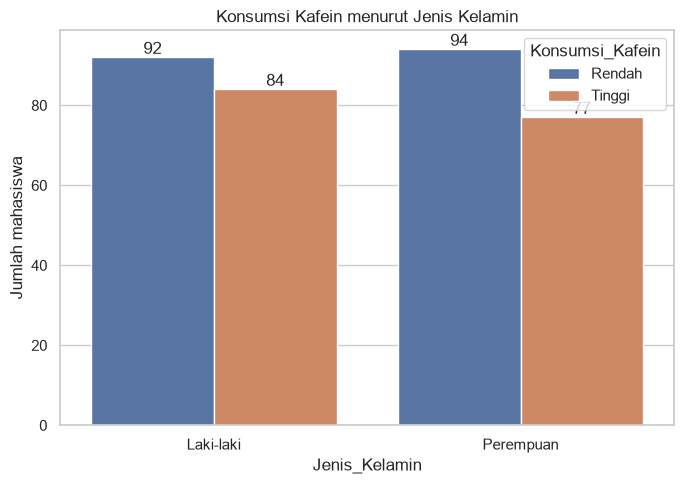

In [43]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x="Jenis_Kelamin", hue="Konsumsi_Kafein",
              hue_order=["Rendah", "Tinggi"], ax=ax)
for c in ax.containers:
    ax.bar_label(c)
ax.set_title("Konsumsi Kafein menurut Jenis Kelamin")
ax.set_ylabel("Jumlah mahasiswa")
plt.tight_layout()
plt.savefig(OUTPUT / "09_grouped_bar_kafein_gender.png", dpi=200)
plt.show()

## 1.8 Grafik Pendukung Analisis
